# SC-Earth station KGE

Kling–Gupta efficiency (KGE) stored with the SC-Earth serially complete station
tables for northwestern North America (about 50–72°N, 172–122°W). Each row is
one GHCN or GSOD station. KGE measures the serially complete estimate against
the quality-controlled observations (Tang, Clark, and Papalexiou, 2021,
[doi:10.1175/JCLI-D-21-0067.1](https://doi.org/10.1175/JCLI-D-21-0067.1)).

The stored components satisfy

$$
\mathrm{KGE} = 1 - \sqrt{(r-1)^2 + (\alpha-1)^2 + (\beta-1)^2}
$$

where \(r\) is correlation, \(\alpha\) is the variability ratio, and the column
`kge_bias_ratio` is \(\beta-1\) rather than \(\beta\).

Figures are sized for a double journal column and written to `figs/sc_earth_kge/`
as PDF and 300 dpi PNG.

In [5]:
from pathlib import Path

import geopandas as gpd
import matplotlib as mpl
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import rasterio
import seaborn as sns
from matplotlib.ticker import FuncFormatter, MultipleLocator
from rasterio.enums import Resampling
from rasterio.windows import Window, bounds as window_bounds, from_bounds
from shapely.geometry import box

mpl.rcParams.update({
    "font.family": "Arial",
    "font.size": 8,
    "axes.labelsize": 9,
    "axes.titlesize": 9,
    "axes.linewidth": 0.6,
    "axes.unicode_minus": False,
    "xtick.labelsize": 8,
    "ytick.labelsize": 8,
    "legend.fontsize": 8,
    "xtick.major.width": 0.6,
    "ytick.major.width": 0.6,
    "xtick.major.size": 3,
    "ytick.major.size": 3,
    "pdf.fonttype": 42,
    "ps.fonttype": 42,
    "figure.dpi": 120,
    "savefig.dpi": 300,
    "savefig.bbox": "tight",
    "savefig.pad_inches": 0.04,
    "figure.facecolor": "white",
    "axes.facecolor": "white",
    "axes.spines.top": False,
    "axes.spines.right": False,
})

DATA_DIR = Path("/Users/dcasson/Data/pems/sc_earth")
DEM_PATH = Path("/Users/dcasson/Data/GISData/MERITHydro/MERIT_Hydro_dem_NA.tif")
COAST_PATH = Path("/Users/dcasson/Data/GISData/coastline/ne_10m_coastline.shp")
COUNTRIES_PATH = Path("/Users/dcasson/Data/GISData/World_Countries.gpkg")
FIG_DIR = Path(
    "/Users/dcasson/GitHub/gpep_snakemake/workflow/notebooks/visualization/figs/sc_earth_kge"
)

# Okabe–Ito colors, shared by every figure.
VARIABLES = [
    {"key": "prcp", "label": "Precipitation", "short": "Precip.", "color": "#0072B2"},
    {"key": "tmean", "label": "Mean temperature", "short": "Tmean", "color": "#D55E00"},
    {"key": "trange", "label": "Temperature range", "short": "Trange", "color": "#009E73"},
    {"key": "wind", "label": "Wind", "short": "Wind", "color": "#CC79A7"},
]
FILE_FOR = {spec["key"]: DATA_DIR / f"SC-Earth_{spec['key']}_complete_metadata.csv" for spec in VARIABLES}
SHORT = [spec["short"] for spec in VARIABLES]
PALETTE = {spec["short"]: spec["color"] for spec in VARIABLES}


def save_figure(fig, name):
    FIG_DIR.mkdir(parents=True, exist_ok=True)
    png = FIG_DIR / f"{name}.png"
    pdf = FIG_DIR / f"{name}.pdf"
    fig.savefig(png)
    fig.savefig(pdf)
    print(png)
    print(pdf)


def style_distribution_axis(ax):
    ax.tick_params(direction="out", length=3, width=0.6)
    ax.yaxis.grid(True, linestyle=":", linewidth=0.4, color="0.75", zorder=0)
    ax.set_axisbelow(True)
    ax.set_xlabel("")


def panel_letter(ax, letter, pad_box=False, fontsize=10):
    kwargs = dict(
        transform=ax.transAxes,
        ha="left",
        va="top",
        fontsize=fontsize,
        fontweight="bold",
        color="black",
        zorder=5,
    )
    if pad_box:
        kwargs["bbox"] = dict(
            boxstyle="square,pad=0.12",
            facecolor="white",
            edgecolor="none",
            alpha=0.9,
        )
    ax.text(0.02, 0.98, letter, **kwargs)

### Station tables

`kge_bias_ratio` is checked against the KGE definition above. A reconstruction
error larger than \(10^{-5}\) means the component columns are not the terms in
that equation.

In [6]:
frames = []
for spec in VARIABLES:
    frame = pd.read_csv(FILE_FOR[spec["key"]])
    frame["key"] = spec["key"]
    frame["label"] = spec["label"]
    frame["short"] = spec["short"]
    frames.append(frame)

stations = pd.concat(frames, ignore_index=True)
stations["network"] = stations["station_id"].str.split("_").str[0]
stations["beta_minus_one"] = stations["kge_bias_ratio"]

reconstructed = 1.0 - np.sqrt(
    (stations["kge_correlation"] - 1.0) ** 2
    + (stations["kge_variability_ratio"] - 1.0) ** 2
    + stations["beta_minus_one"] ** 2
)
max_abs_error = float((reconstructed - stations["kge"]).abs().max())
if max_abs_error > 1e-5:
    raise ValueError(f"KGE identity failed; max abs error = {max_abs_error:.3e}")

print(f"Stations: {len(stations)}")
print(f"Max |reconstructed KGE − reported KGE| = {max_abs_error:.2e}")
print(
    "Longitude {west:.2f} to {east:.2f}, latitude {south:.2f} to {north:.2f}".format(
        west=stations["longitude"].min(),
        east=stations["longitude"].max(),
        south=stations["latitude"].min(),
        north=stations["latitude"].max(),
    )
)
stations.groupby("label").size().rename("n")

Stations: 2077
Max |reconstructed KGE − reported KGE| = 5.30e-08
Longitude -171.73 to -122.05, latitude 50.02 to 72.00


label
Mean temperature     695
Precipitation        451
Temperature range    673
Wind                 258
Name: n, dtype: int64

### Summary of the KGE distribution

Percentiles describe the station sample. Component columns are the median of
correlation and of the variability ratio, and the largest absolute bias term.

In [7]:
def _percentile_row(values, label):
    return {
        "Variable": label,
        "N": int(values.count()),
        "Min": values.min(),
        "P05": values.quantile(0.05),
        "P25": values.quantile(0.25),
        "Median": values.median(),
        "P75": values.quantile(0.75),
        "P95": values.quantile(0.95),
        "Max": values.max(),
    }


kge_summary = pd.DataFrame(
    [
        _percentile_row(stations.loc[stations["key"] == spec["key"], "kge"], spec["label"])
        for spec in VARIABLES
    ]
)
network_counts = (
    stations.groupby(["label", "network"]).size().unstack(fill_value=0).reindex(kge_summary["Variable"])
)
kge_summary.insert(2, "GHCN", network_counts["GHCN"].to_numpy())
kge_summary.insert(3, "GSOD", network_counts["GSOD"].to_numpy())

component_summary = []
for spec in VARIABLES:
    part = stations.loc[stations["key"] == spec["key"]]
    component_summary.append(
        {
            "Variable": spec["label"],
            "r median": part["kge_correlation"].median(),
            "r min": part["kge_correlation"].min(),
            "r max": part["kge_correlation"].max(),
            "alpha median": part["kge_variability_ratio"].median(),
            "alpha min": part["kge_variability_ratio"].min(),
            "alpha max": part["kge_variability_ratio"].max(),
            "max |beta-1|": part["beta_minus_one"].abs().max(),
        }
    )
component_summary = pd.DataFrame(component_summary)

FIG_DIR.mkdir(parents=True, exist_ok=True)
kge_summary.to_csv(FIG_DIR / "kge_summary.csv", index=False)
component_summary.to_csv(FIG_DIR / "kge_component_summary.csv", index=False)

float_cols = [col for col in kge_summary.columns if col not in ("Variable", "N", "GHCN", "GSOD")]
display(kge_summary.style.format({col: "{:.3f}" for col in float_cols}).hide(axis="index"))
display(
    component_summary.style.format(
        {col: "{:.3f}" if col != "max |beta-1|" else "{:.2e}" for col in component_summary.columns if col != "Variable"}
    ).hide(axis="index")
)

Variable,N,GHCN,GSOD,Min,P05,P25,Median,P75,P95,Max
Precipitation,451,356,95,0.104,0.575,0.737,0.816,0.872,0.928,0.970
Mean temperature,695,454,241,0.900,0.971,0.984,0.989,0.992,0.996,0.999
Temperature range,673,454,219,0.465,0.713,0.798,0.855,0.898,0.948,0.985
Wind,258,24,234,0.404,0.639,0.745,0.811,0.875,0.925,0.959


Variable,r median,r min,r max,alpha median,alpha min,alpha max,max |beta-1|
Precipitation,0.845,0.108,0.987,1.078,0.890,1.329,4.85e-03
Mean temperature,0.991,0.900,0.999,0.998,0.957,1.042,8.27e-06
Temperature range,0.855,0.465,0.985,1.001,0.952,1.107,3.37e-05
Wind,0.861,0.448,0.976,1.102,0.997,1.374,2.70e-06


### Range and distribution of KGE

White points are medians. Thick bars are the interquartile range, and thin bars
are the full sample range. Violin width is probability density, clipped to the
observed range. The empirical CDF uses the same colors.

/Users/dcasson/GitHub/gpep_snakemake/workflow/notebooks/visualization/figs/sc_earth_kge/kge_distribution.png
/Users/dcasson/GitHub/gpep_snakemake/workflow/notebooks/visualization/figs/sc_earth_kge/kge_distribution.pdf


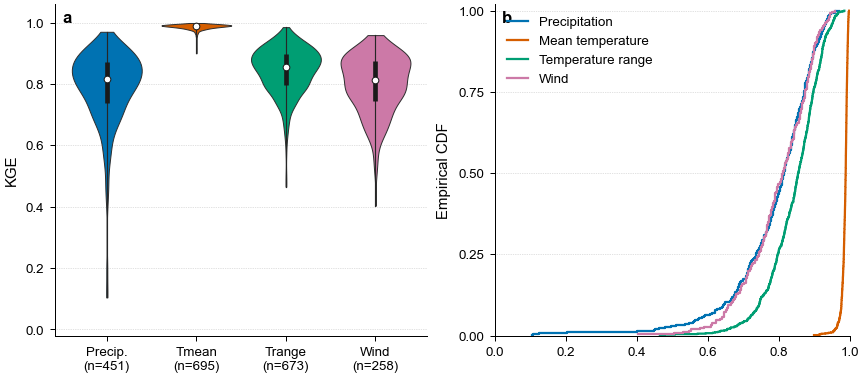

In [8]:
def draw_range_violins(ax, column, ylim, hline=None):
    """Violin of one column, with the sample range and interquartile bar."""
    sns.violinplot(
        data=stations,
        x="short",
        y=column,
        hue="short",
        order=SHORT,
        hue_order=SHORT,
        palette=PALETTE,
        cut=0,
        inner=None,
        linewidth=0.6,
        saturation=1,
        density_norm="width",
        width=0.78,
        legend=False,
        ax=ax,
    )
    for index, spec in enumerate(VARIABLES):
        values = stations.loc[stations["key"] == spec["key"], column].to_numpy()
        q1, median, q3 = np.percentile(values, [25, 50, 75])
        ax.plot([index, index], [values.min(), values.max()], color="0.15", lw=0.7, zorder=3)
        ax.plot(
            [index, index],
            [q1, q3],
            color="0.1",
            lw=2.8,
            zorder=4,
            solid_capstyle="butt",
        )
        ax.scatter(
            [index],
            [median],
            s=16,
            c="white",
            edgecolors="0.1",
            linewidths=0.6,
            zorder=5,
        )
    if hline is not None:
        ax.axhline(hline, color="0.35", lw=0.6, ls="--", zorder=1)
    ax.set_ylim(*ylim)
    style_distribution_axis(ax)
    return ax


def draw_kge_ecdf(ax):
    for spec in VARIABLES:
        values = np.sort(stations.loc[stations["key"] == spec["key"], "kge"].to_numpy())
        probability = np.arange(1, len(values) + 1) / len(values)
        ax.step(
            values,
            probability,
            where="post",
            color=spec["color"],
            lw=1.35,
            label=spec["label"],
        )
    ax.set_xlim(0, 1)
    ax.set_ylim(0, 1.02)
    ax.set_xlabel("KGE")
    ax.set_ylabel("Empirical CDF")
    ax.set_yticks([0, 0.25, 0.5, 0.75, 1.0])
    ax.legend(frameon=False, loc="upper left", handlelength=1.6)
    style_distribution_axis(ax)


fig, axes = plt.subplots(1, 2, figsize=(7.2, 3.15), constrained_layout=True, gridspec_kw={"width_ratios": [1.05, 1]})
draw_range_violins(axes[0], "kge", ylim=(-0.02, 1.06))
axes[0].set_ylabel("KGE")
axes[0].set_yticks([0, 0.2, 0.4, 0.6, 0.8, 1.0])
counts = stations.groupby("key").size()
axes[0].set_xticks(range(len(VARIABLES)))
axes[0].set_xticklabels([f"{spec['short']}\n(n={counts[spec['key']]})" for spec in VARIABLES])
draw_kge_ecdf(axes[1])
panel_letter(axes[0], "a")
panel_letter(axes[1], "b")
save_figure(fig, "kge_distribution")
plt.show()

### KGE components

Correlation and the variability ratio account for essentially all of the KGE
deficit. Panel (c) is the station-median share of \((r-1)^2\) and \((lpha-1)^2\).
The bias share is below 0.001% at the median station and is left off the bar.
The largest \(|\beta-1|\) in the sample is still smaller than \(2 \times 10^{-3}\).
A variability ratio above the dashed line means the serially complete series
varies more than the observations.

/Users/dcasson/GitHub/gpep_snakemake/workflow/notebooks/visualization/figs/sc_earth_kge/kge_components.png
/Users/dcasson/GitHub/gpep_snakemake/workflow/notebooks/visualization/figs/sc_earth_kge/kge_components.pdf


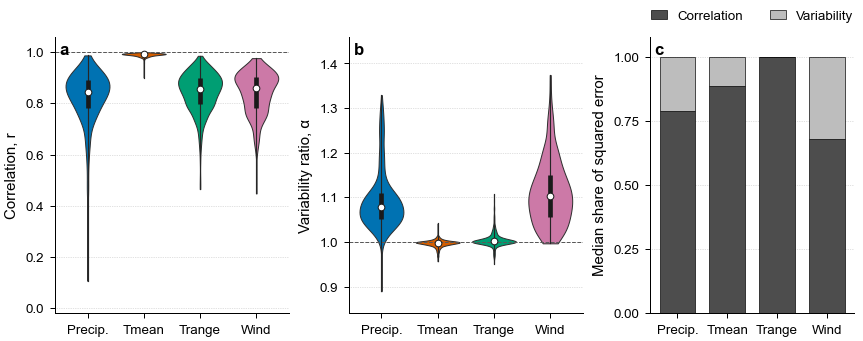

In [9]:
squared_r = (stations["kge_correlation"] - 1.0) ** 2
squared_alpha = (stations["kge_variability_ratio"] - 1.0) ** 2
squared_bias = stations["beta_minus_one"] ** 2
squared_total = squared_r + squared_alpha + squared_bias
stations["share_r"] = squared_r / squared_total
stations["share_alpha"] = squared_alpha / squared_total

fig, axes = plt.subplots(
    1, 3, figsize=(7.2, 2.85), constrained_layout=True, gridspec_kw={"width_ratios": [1.15, 1.15, 1]}
)
draw_range_violins(axes[0], "kge_correlation", ylim=(-0.02, 1.06), hline=1)
axes[0].set_ylabel("Correlation, r")
axes[0].set_yticks([0, 0.2, 0.4, 0.6, 0.8, 1.0])

draw_range_violins(axes[1], "kge_variability_ratio", ylim=(0.84, 1.46), hline=1)
axes[1].set_ylabel("Variability ratio, α")

share_r = [stations.loc[stations["key"] == spec["key"], "share_r"].median() for spec in VARIABLES]
share_alpha = [stations.loc[stations["key"] == spec["key"], "share_alpha"].median() for spec in VARIABLES]
x = np.arange(len(VARIABLES))
axes[2].bar(x, share_r, width=0.72, color="#4D4D4D", edgecolor="black", linewidth=0.4, label="Correlation")
axes[2].bar(
    x,
    share_alpha,
    width=0.72,
    bottom=share_r,
    color="#BDBDBD",
    edgecolor="black",
    linewidth=0.4,
    label="Variability",
)
axes[2].set_xticks(x)
axes[2].set_xticklabels(SHORT)
axes[2].set_ylim(0, 1.08)
axes[2].set_yticks([0, 0.25, 0.5, 0.75, 1.0])
axes[2].set_ylabel("Median share of squared error")
axes[2].legend(frameon=False, loc="lower center", bbox_to_anchor=(0.5, 1.01), ncol=2, handlelength=1.2)
style_distribution_axis(axes[2])

for ax, letter in zip(axes, "abc"):
    panel_letter(ax, letter)

save_figure(fig, "kge_components")
plt.show()

### KGE and elevation

Points are stations. The black line is the median KGE in elevation bins of 0–100, 100–300, 300–600, 600–1000, and 1000–2000 m, placed at the median elevation of the stations in that bin. Bins with fewer than 8 stations are omitted. Spearman’s rank correlation uses every station.


/Users/dcasson/GitHub/gpep_snakemake/workflow/notebooks/visualization/figs/sc_earth_kge/kge_vs_elevation.png
/Users/dcasson/GitHub/gpep_snakemake/workflow/notebooks/visualization/figs/sc_earth_kge/kge_vs_elevation.pdf


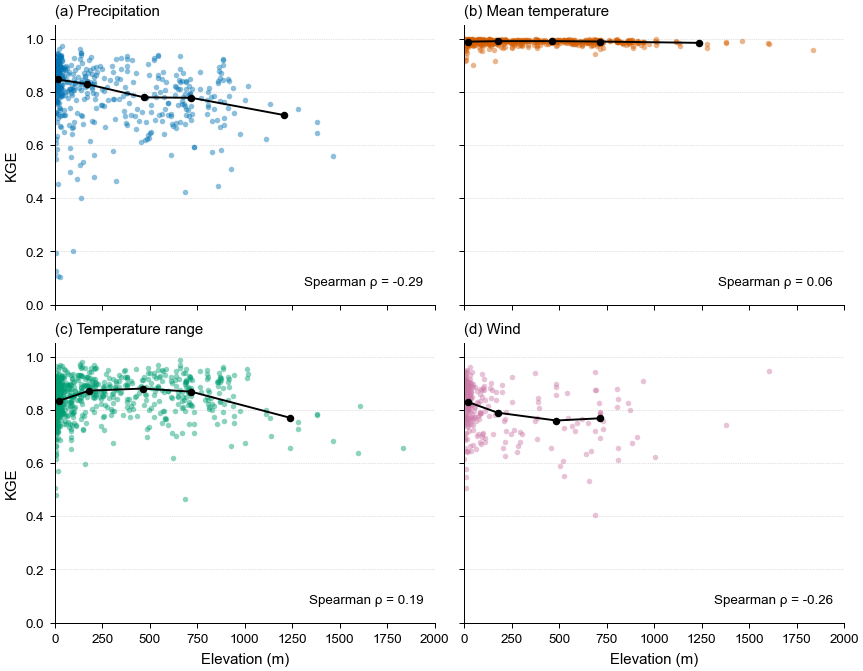

In [10]:
def binned_median(elevation, kge, edges, min_count=8):
    centers = []
    medians = []
    for lower, upper in zip(edges[:-1], edges[1:]):
        if upper == edges[-1]:
            chosen = (elevation >= lower) & (elevation <= upper)
        else:
            chosen = (elevation >= lower) & (elevation < upper)
        if int(chosen.sum()) >= min_count:
            centers.append(float(np.median(elevation[chosen])))
            medians.append(float(np.median(kge[chosen])))
        else:
            centers.append(np.nan)
            medians.append(np.nan)
    return np.asarray(centers), np.asarray(medians)


edges = np.array([0, 100, 300, 600, 1000, 2000])
fig, axes = plt.subplots(2, 2, figsize=(7.2, 5.6), sharex=True, sharey=True, constrained_layout=True)
for ax, spec, letter in zip(axes.flat, VARIABLES, "abcd"):
    part = stations.loc[stations["key"] == spec["key"]]
    elevation = part["elevation_m"].to_numpy()
    kge = part["kge"].to_numpy()
    ax.scatter(
        elevation,
        kge,
        s=11,
        c=spec["color"],
        alpha=0.45,
        linewidths=0,
        zorder=2,
    )
    centers, medians = binned_median(elevation, kge, edges)
    ax.plot(centers, medians, color="black", lw=1.15, marker="o", ms=3.5, zorder=3)
    rho = pd.Series(elevation).corr(pd.Series(kge), method="spearman")
    ax.text(
        0.97,
        0.06,
        f"Spearman ρ = {rho:.2f}",
        transform=ax.transAxes,
        ha="right",
        va="bottom",
    )
    ax.set_title(f"({letter}) {spec['label']}", loc="left", fontsize=9)
    ax.set_xlim(0, 2000)
    ax.set_ylim(0, 1.05)
    ax.set_yticks([0, 0.2, 0.4, 0.6, 0.8, 1.0])
    style_distribution_axis(ax)

for ax in axes[1, :]:
    ax.set_xlabel("Elevation (m)")
for ax in axes[:, 0]:
    ax.set_ylabel("KGE")

save_figure(fig, "kge_vs_elevation")
plt.show()

### Station maps

Same drawing order as `plot_dem_with_two_stations` and the metric panels in
`static_data_visualization.ipynb`: a `Greys` DEM, a black geographic outline,
then stations. Station color is KGE on a shared scale from 0 to 1. Low-KGE
stations are drawn last so they sit on top of the cluster.

The background is a 0.02° average of MERIT Hydro (`MERIT_Hydro_dem_NA.tif`),
because these stations extend past any single catchment DEM. Elevations above
the 99th percentile of land cells saturate so the lowlands keep contrast. The
outline is the Natural Earth 10 m coastline plus the Canada–United States border.

In [11]:
# Window that contains every station, with a small margin.
pad = 0.6
west = float(stations["longitude"].min()) - pad
east = float(stations["longitude"].max()) + pad
south = float(stations["latitude"].min()) - pad
north = float(stations["latitude"].max()) + pad
target_resolution = 0.02

with rasterio.open(DEM_PATH) as dem_source:
    window = from_bounds(west, south, east, north, dem_source.transform)
    window = window.round_offsets(op="floor").round_lengths(op="ceil")
    window = window.intersection(Window(0, 0, dem_source.width, dem_source.height))
    left, bottom, right, top = window_bounds(window, dem_source.transform)
    out_height = int(round((top - bottom) / target_resolution))
    out_width = int(round((right - left) / target_resolution))
    dem = dem_source.read(
        1,
        window=window,
        out_shape=(out_height, out_width),
        resampling=Resampling.average,
    )

dem = dem.astype("float32")
dem[dem < -50] = np.nan
dem_extent = [left, right, bottom, top]
dem_vmax = float(np.nanpercentile(dem, 99))
print(
    f"DEM window {dem.shape[1]} x {dem.shape[0]} cells, "
    f"elevation color scale 0 to {dem_vmax:.0f} m"
)

map_box = box(left, bottom, right, top)
coastline = gpd.read_file(COAST_PATH, bbox=(left, bottom, right, top))
coastline = gpd.clip(coastline, map_box)

countries = gpd.read_file(COUNTRIES_PATH)
countries = countries.loc[countries["ISO"].isin(["US", "CA"]), ["ISO", "geometry"]].to_crs(4326)
countries = gpd.clip(countries, map_box)
united_states = countries.loc[countries["ISO"] == "US"].geometry.unary_union
canada = countries.loc[countries["ISO"] == "CA"].geometry.unary_union
border = gpd.GeoSeries(
    [united_states.boundary.intersection(canada.boundary)],
    crs="EPSG:4326",
)
print(f"Coastline parts: {len(coastline)}")

DEM window 2544 x 1159 cells, elevation color scale 0 to 2072 m
Coastline parts: 249


/var/folders/46/6y3tkg051374dmsgd2w6l9gw0000gn/T/ipykernel_17962/2150815386.py:39: DeprecationWarning: The 'unary_union' attribute is deprecated, use the 'union_all()' method instead.
  united_states = countries.loc[countries["ISO"] == "US"].geometry.unary_union
/var/folders/46/6y3tkg051374dmsgd2w6l9gw0000gn/T/ipykernel_17962/2150815386.py:40: DeprecationWarning: The 'unary_union' attribute is deprecated, use the 'union_all()' method instead.
  canada = countries.loc[countries["ISO"] == "CA"].geometry.unary_union


/Users/dcasson/GitHub/gpep_snakemake/workflow/notebooks/visualization/figs/sc_earth_kge/kge_station_maps.png
/Users/dcasson/GitHub/gpep_snakemake/workflow/notebooks/visualization/figs/sc_earth_kge/kge_station_maps.pdf


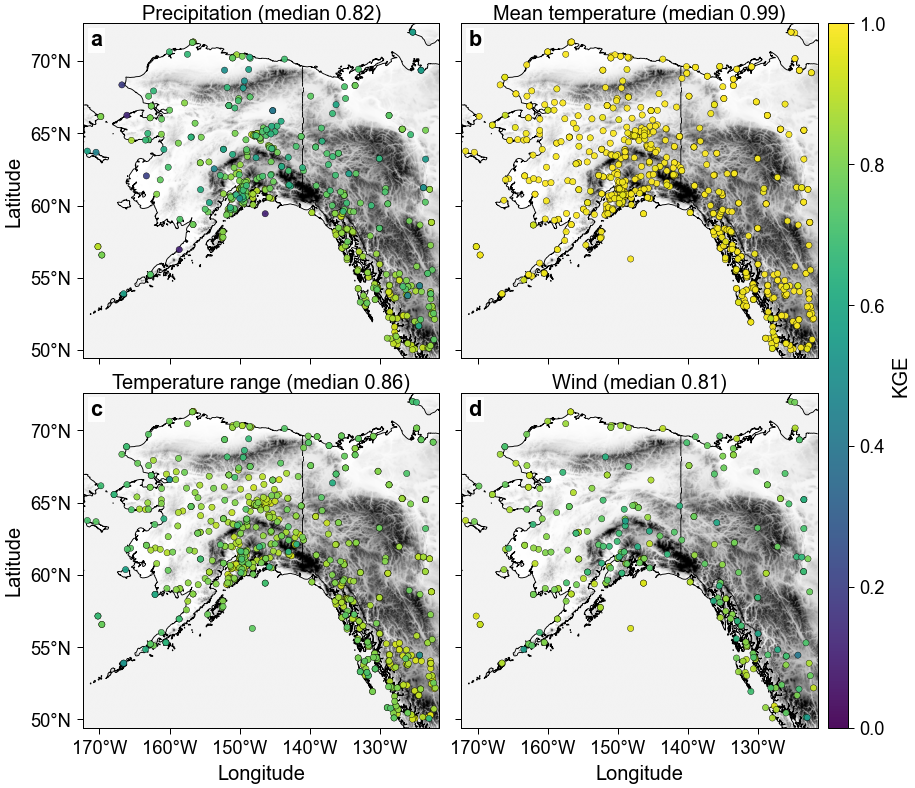

In [12]:
def plot_dem_kge(ax, lon, lat, kge, title):
    """Grey DEM, black outline, stations colored by KGE.

    Matches the metric maps in the static-data notebook: ``Greys`` image,
    boundary outline, then a scatter whose color is the metric. Limits stay on
    the DEM extent.
    """
    terrain = mpl.colormaps["Greys"].copy()
    terrain.set_bad("#f3f3f3")
    ax.imshow(
        np.ma.masked_invalid(dem),
        extent=dem_extent,
        cmap=terrain,
        vmin=0,
        vmax=dem_vmax,
        interpolation="bilinear",
        origin="upper",
        zorder=0,
    )
    coastline.plot(ax=ax, color="black", linewidth=0.55, zorder=2)
    border.plot(ax=ax, color="black", linewidth=0.55, zorder=2)

    # Draw high KGE first so low scores remain visible in dense clusters.
    order = np.argsort(-np.asarray(kge))
    lon = np.asarray(lon)[order]
    lat = np.asarray(lat)[order]
    kge = np.asarray(kge)[order]
    stations_artist = ax.scatter(
        lon,
        lat,
        c=kge,
        cmap="viridis",
        vmin=0,
        vmax=1,
        s=14,
        alpha=0.95,
        edgecolors="black",
        linewidths=0.25,
        zorder=3,
    )
    ax.set_xlim(dem_extent[0], dem_extent[1])
    ax.set_ylim(dem_extent[2], dem_extent[3])
    latitude_center = 0.5 * (dem_extent[2] + dem_extent[3])
    ax.set_aspect(1.0 / np.cos(np.deg2rad(latitude_center)))
    ax.set_title(title, pad=2, fontsize=12)
    ax.xaxis.set_major_locator(MultipleLocator(10))
    ax.yaxis.set_major_locator(MultipleLocator(5))
    ax.xaxis.set_major_formatter(FuncFormatter(lambda value, _pos: f"{abs(value):.0f}°W"))
    ax.yaxis.set_major_formatter(FuncFormatter(lambda value, _pos: f"{value:.0f}°N"))
    ax.tick_params(
        direction="out",
        length=3.5,
        width=0.6,
        top=False,
        right=False,
        labelsize=11,
    )
    for spine in ax.spines.values():
        spine.set_visible(True)
        spine.set_linewidth(0.6)
    return stations_artist


fig = plt.figure(figsize=(7.6, 6.85))
fig.set_layout_engine(
    "compressed",
    h_pad=0.02,
    w_pad=0.025,
    hspace=0.0,
    wspace=0.035,
)
gs = fig.add_gridspec(2, 3, width_ratios=[1, 1, 0.055])
axes = np.empty((2, 2), dtype=object)
for row in range(2):
    for col in range(2):
        axes[row, col] = fig.add_subplot(gs[row, col])
cax = fig.add_subplot(gs[:, 2])

artists = []
for ax, spec, letter in zip(axes.flat, VARIABLES, "abcd"):
    part = stations.loc[stations["key"] == spec["key"]]
    median_kge = part["kge"].median()
    artist = plot_dem_kge(
        ax,
        part["longitude"],
        part["latitude"],
        part["kge"],
        f"{spec['label']} (median {median_kge:.2f})",
    )
    artists.append(artist)
    panel_letter(ax, letter, pad_box=True, fontsize=13)

for ax in axes[0, :]:
    ax.tick_params(labelbottom=False)
for ax in axes[:, 1]:
    ax.tick_params(labelleft=False)
for ax in axes[:, 0]:
    ax.set_ylabel("Latitude", fontsize=12)
for ax in axes[1, :]:
    ax.set_xlabel("Longitude", fontsize=12)

color_scale = fig.colorbar(artists[0], cax=cax)
color_scale.outline.set_linewidth(0.6)
color_scale.ax.tick_params(length=3.5, width=0.6, labelsize=11)
color_scale.set_label("KGE", fontsize=12)
color_scale.set_ticks([0, 0.2, 0.4, 0.6, 0.8, 1.0])

save_figure(fig, "kge_station_maps")
plt.show()

### Reading the figures

Mean temperature is a different result from the other three variables: KGE sits against 1 at nearly every station, including the high-elevation ones. Temperature range is lower, and that gap is almost entirely correlation; the variability ratio stays on 1. Wind and precipitation are centered near 0.8 and have a long lower tail, precipitation especially. Both also have variability ratios above 1, so the serially complete series varies more than the observations, and that term is a substantial part of the KGE deficit. Bias does not contribute.

On the maps, mean temperature has little spatial structure because those values occupy only the top of the shared scale. Precipitation, temperature range, and wind show where the weaker stations sit. The elevation panels are the companion to that map: wind and precipitation medians decline toward higher stations, temperature range is slightly higher through the middle elevations and lower above 1000 m, and mean temperature does not vary with elevation.
